In [1]:
import jax
import os

# # Avoid OOM errors
# os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"]=".66"
# # os.environ["XLA_PYTHON_CLIENT_PREALLOCATE"]="false"
# print(f"JAX backend: {jax.default_backend()}")

In [2]:
import sys
sys.path.append("../")

%load_ext autoreload
%autoreload 2

import pulse_simulator as ps

/home/andy/Documents/Research/pulse-simulator/.venv/lib/python3.10/site-packages/qiskit_dynamics/dispatch/backends/jax.py:34: UserWarning: The functionality in the perturbation module of Qiskit Dynamics requires a JAX version <= 0.4.6, due to a bug in JAX versions > 0.4.6. For versions 0.4.4, 0.4.5, and 0.4.6, using the perturbation module functionality requires setting os.environ['JAX_JIT_PJIT_API_MERGE'] = '0' before importing JAX or Dynamics.
  warnings.warn(


In [3]:
from datetime import datetime
import functools
import itertools
import logging
import numpy as np
import pickle as pkl
import qiskit as qk
from qiskit import pulse
import qiskit_aer
import qiskit.providers.fake_provider as qk_fp
import qiskit_dynamics as qk_d
import qutip as qt
import re 
from scipy.integrate import simpson
from scipy.linalg import sqrtm, expm
from tqdm import tqdm
import warnings

import matplotlib.pyplot as plt

In [4]:
Units = 1e9

# Undo units
GHz = 1 / Units
MHz = 1e3 / Units
μs = Units / 1e3
ns = Units

backend = qk_fp.FakeManila()
dt = backend.configuration().dt * ns
desired_1qb_duration = 225  # dt
desired_2qb_duration = 225 * 4  # dt

# Gate time in SI units (granularity restriction)
duration_1qb = ps.qiskit_closest_multiple_of_16(desired_1qb_duration * dt / ns, backend)
duration_2qb = ps.qiskit_closest_multiple_of_16(desired_2qb_duration * dt / ns, backend)

# Pulses

We now have a pair of identity gates.

In [5]:
# Load shapes
fname_1qb = "../pico-pulses/saved-pulses-2024-02-16/a_single_qubit_gateset_R1e-5.csv"
pico_a = ps.from_csv(fname_1qb)
pico_a = np.vstack([pico_a, 1.0 * np.ones(pico_a.shape[1])])

names_1qb = ["X1", "X2", "SX1", "SX2", "I1", "I2"]
angles_1qb = [1.5 * np.pi, 0.5 * np.pi, 1.25 * np.pi, 0.25 * np.pi, 0.2, 0.0]

In [6]:
cal_1qb_robust = ps.calibrate_gateset(
    gateset=pico_a,
    names=names_1qb,
    angles=angles_1qb,
    duration=duration_1qb,
    dt=dt,
)

cal_1qb_default = ps.default_single_qubit_gateset(
    names_1qb,
    duration_1qb,
    dt,
)

Storing symbolic pulses...
Adjusting X1 by amplitude 0.20 for angle 1.50π
Adjusting X2 by amplitude 0.20 for angle 0.50π
Adjusting SX1 by amplitude 0.20 for angle 1.25π
Adjusting SX2 by amplitude 0.20 for angle 0.25π
Zero area signal. Adjusting I1 by amplitude 0.20 (using provided angle).
Adjusting I2 by amplitude 0.00 for angle 0.00π


In [7]:
# Load shapes 
def fname(k):
    return f"../pico-pulses/saved-pulses-2024-01-16/a_two_qubit_{k}.csv"

base_2qb = {k: ps.from_csv(fname(k))[0] for k in ["default", "robust"]}
robust_2qb = 2 * [base_2qb["robust"]]
default_2qb = 2 * [base_2qb["default"]]
names_2qb = ["+", "-"]

In [8]:
cal_2qb_robust = ps.calibrate_gateset(
    gateset=robust_2qb,
    names=names_2qb,
    angles=[0.125 * np.pi, -0.125 * np.pi],
    duration=duration_2qb,
    dt=dt,
    samples=51
)

cal_2qb_default = ps.calibrate_gateset(
    gateset=default_2qb,
    names=names_2qb,
    angles=[0.125 * np.pi, -0.125 * np.pi],
    duration=duration_2qb,
    dt=dt,
    samples=51,
)

Storing symbolic pulses...
Adjusting + by amplitude 0.30 for angle 0.12π
Adjusting - by amplitude-0.30 for angle-0.12π
Storing symbolic pulses...
Adjusting + by amplitude 0.30 for angle 0.12π
Adjusting - by amplitude-0.30 for angle-0.12π


## Build QV circuit

In [9]:
registers = [0, 1, 2, 3]

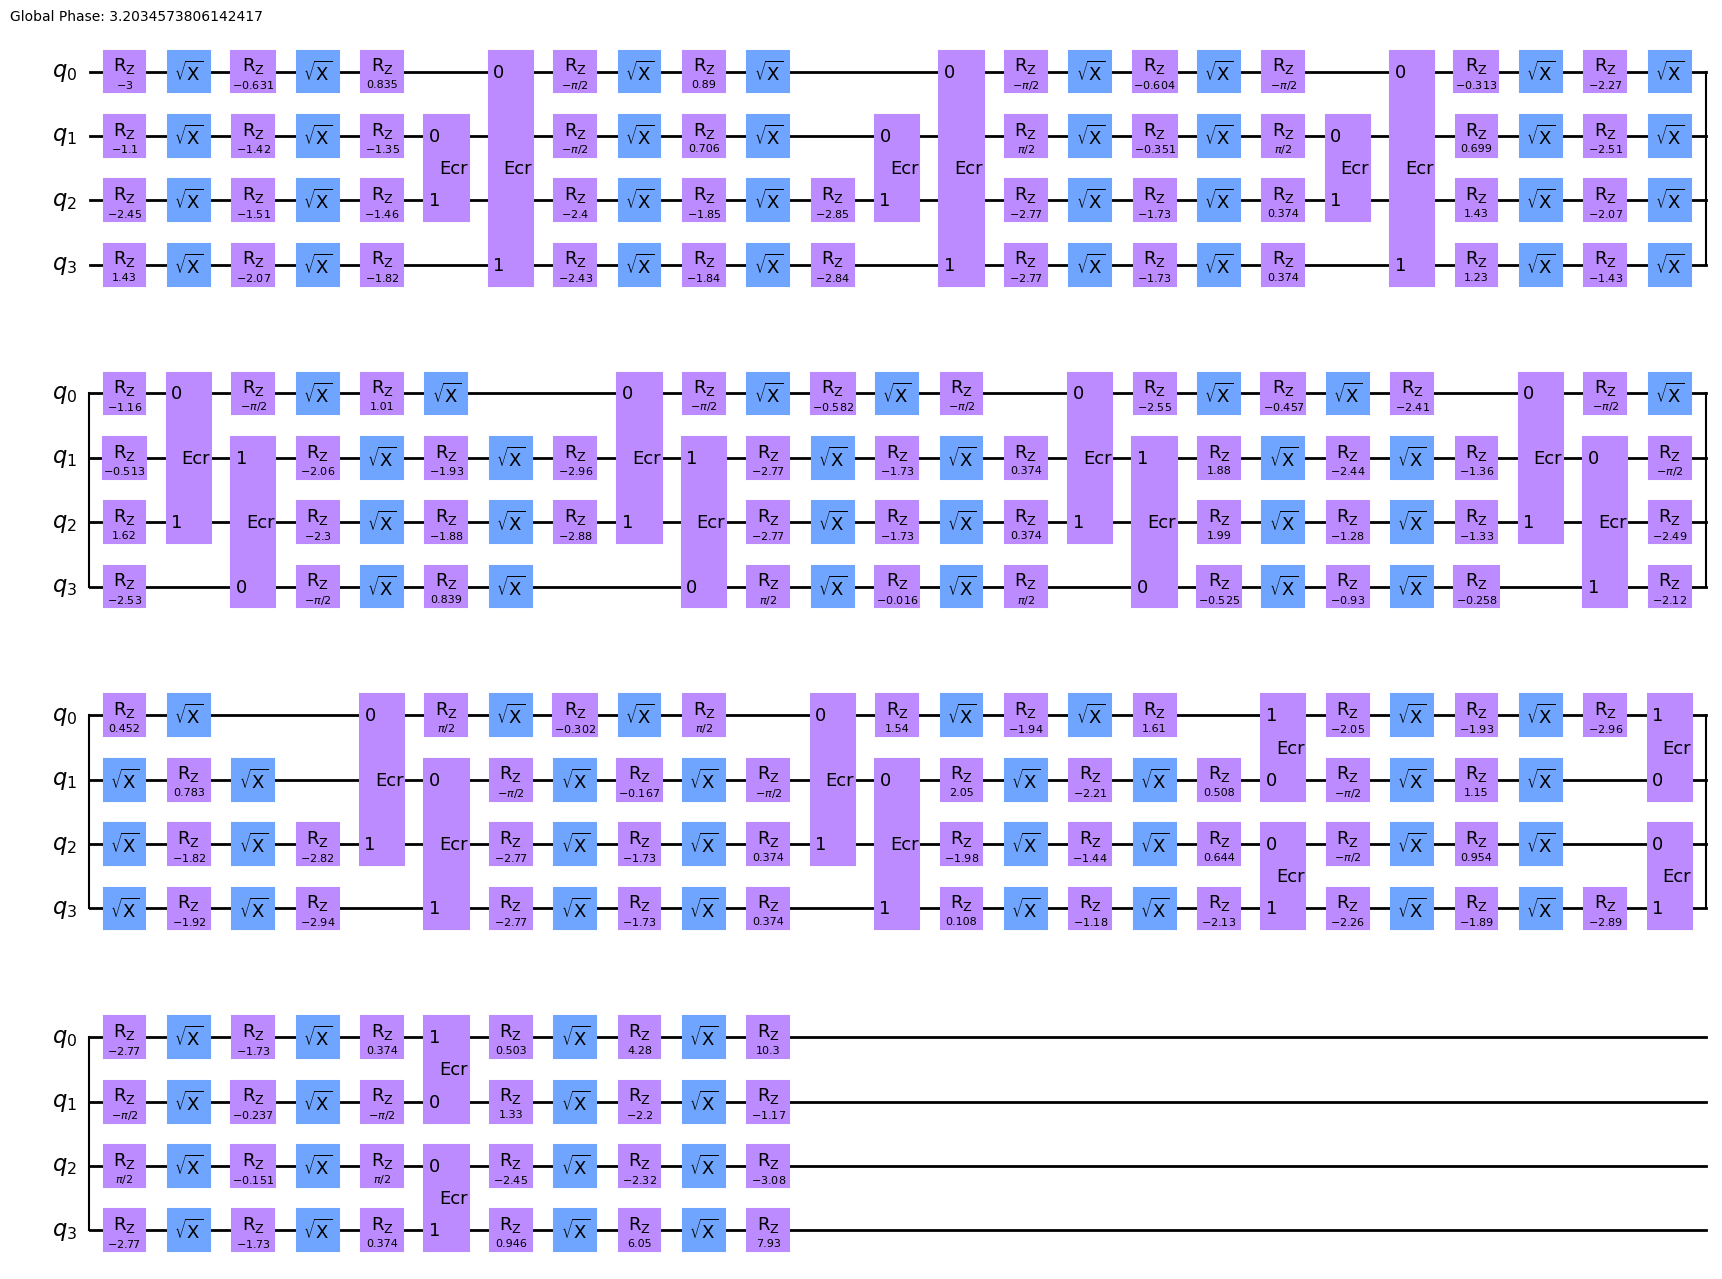

In [14]:
qv = qk.circuit.library.QuantumVolume(num_qubits=4, depth=None, seed=0, classical_permutation=True) 
transpiled_qv = qk.transpile(qv, basis_gates=['ecr','sx','x','rz','id'])

transpiled_qv.draw("mpl")#, fold=-1)

In [12]:
mb = ps.MomentBuilder()

qv_moments = mb.build_moments(
    transpiled_qv, 
    no_end_to_end=True, 
    optimization_level=0, 
)

/home/andy/Documents/Research/pulse-simulator/.venv/lib/python3.10/site-packages/qiskit/visualization/circuit/matplotlib.py:266: FutureWarning: The default matplotlib drawer scheme will be changed to "iqp" in a following release. To silence this warning, specify the current default explicitly as style="clifford", or the new default as style="iqp".
  self._style, def_font_ratio = load_style(self._style)


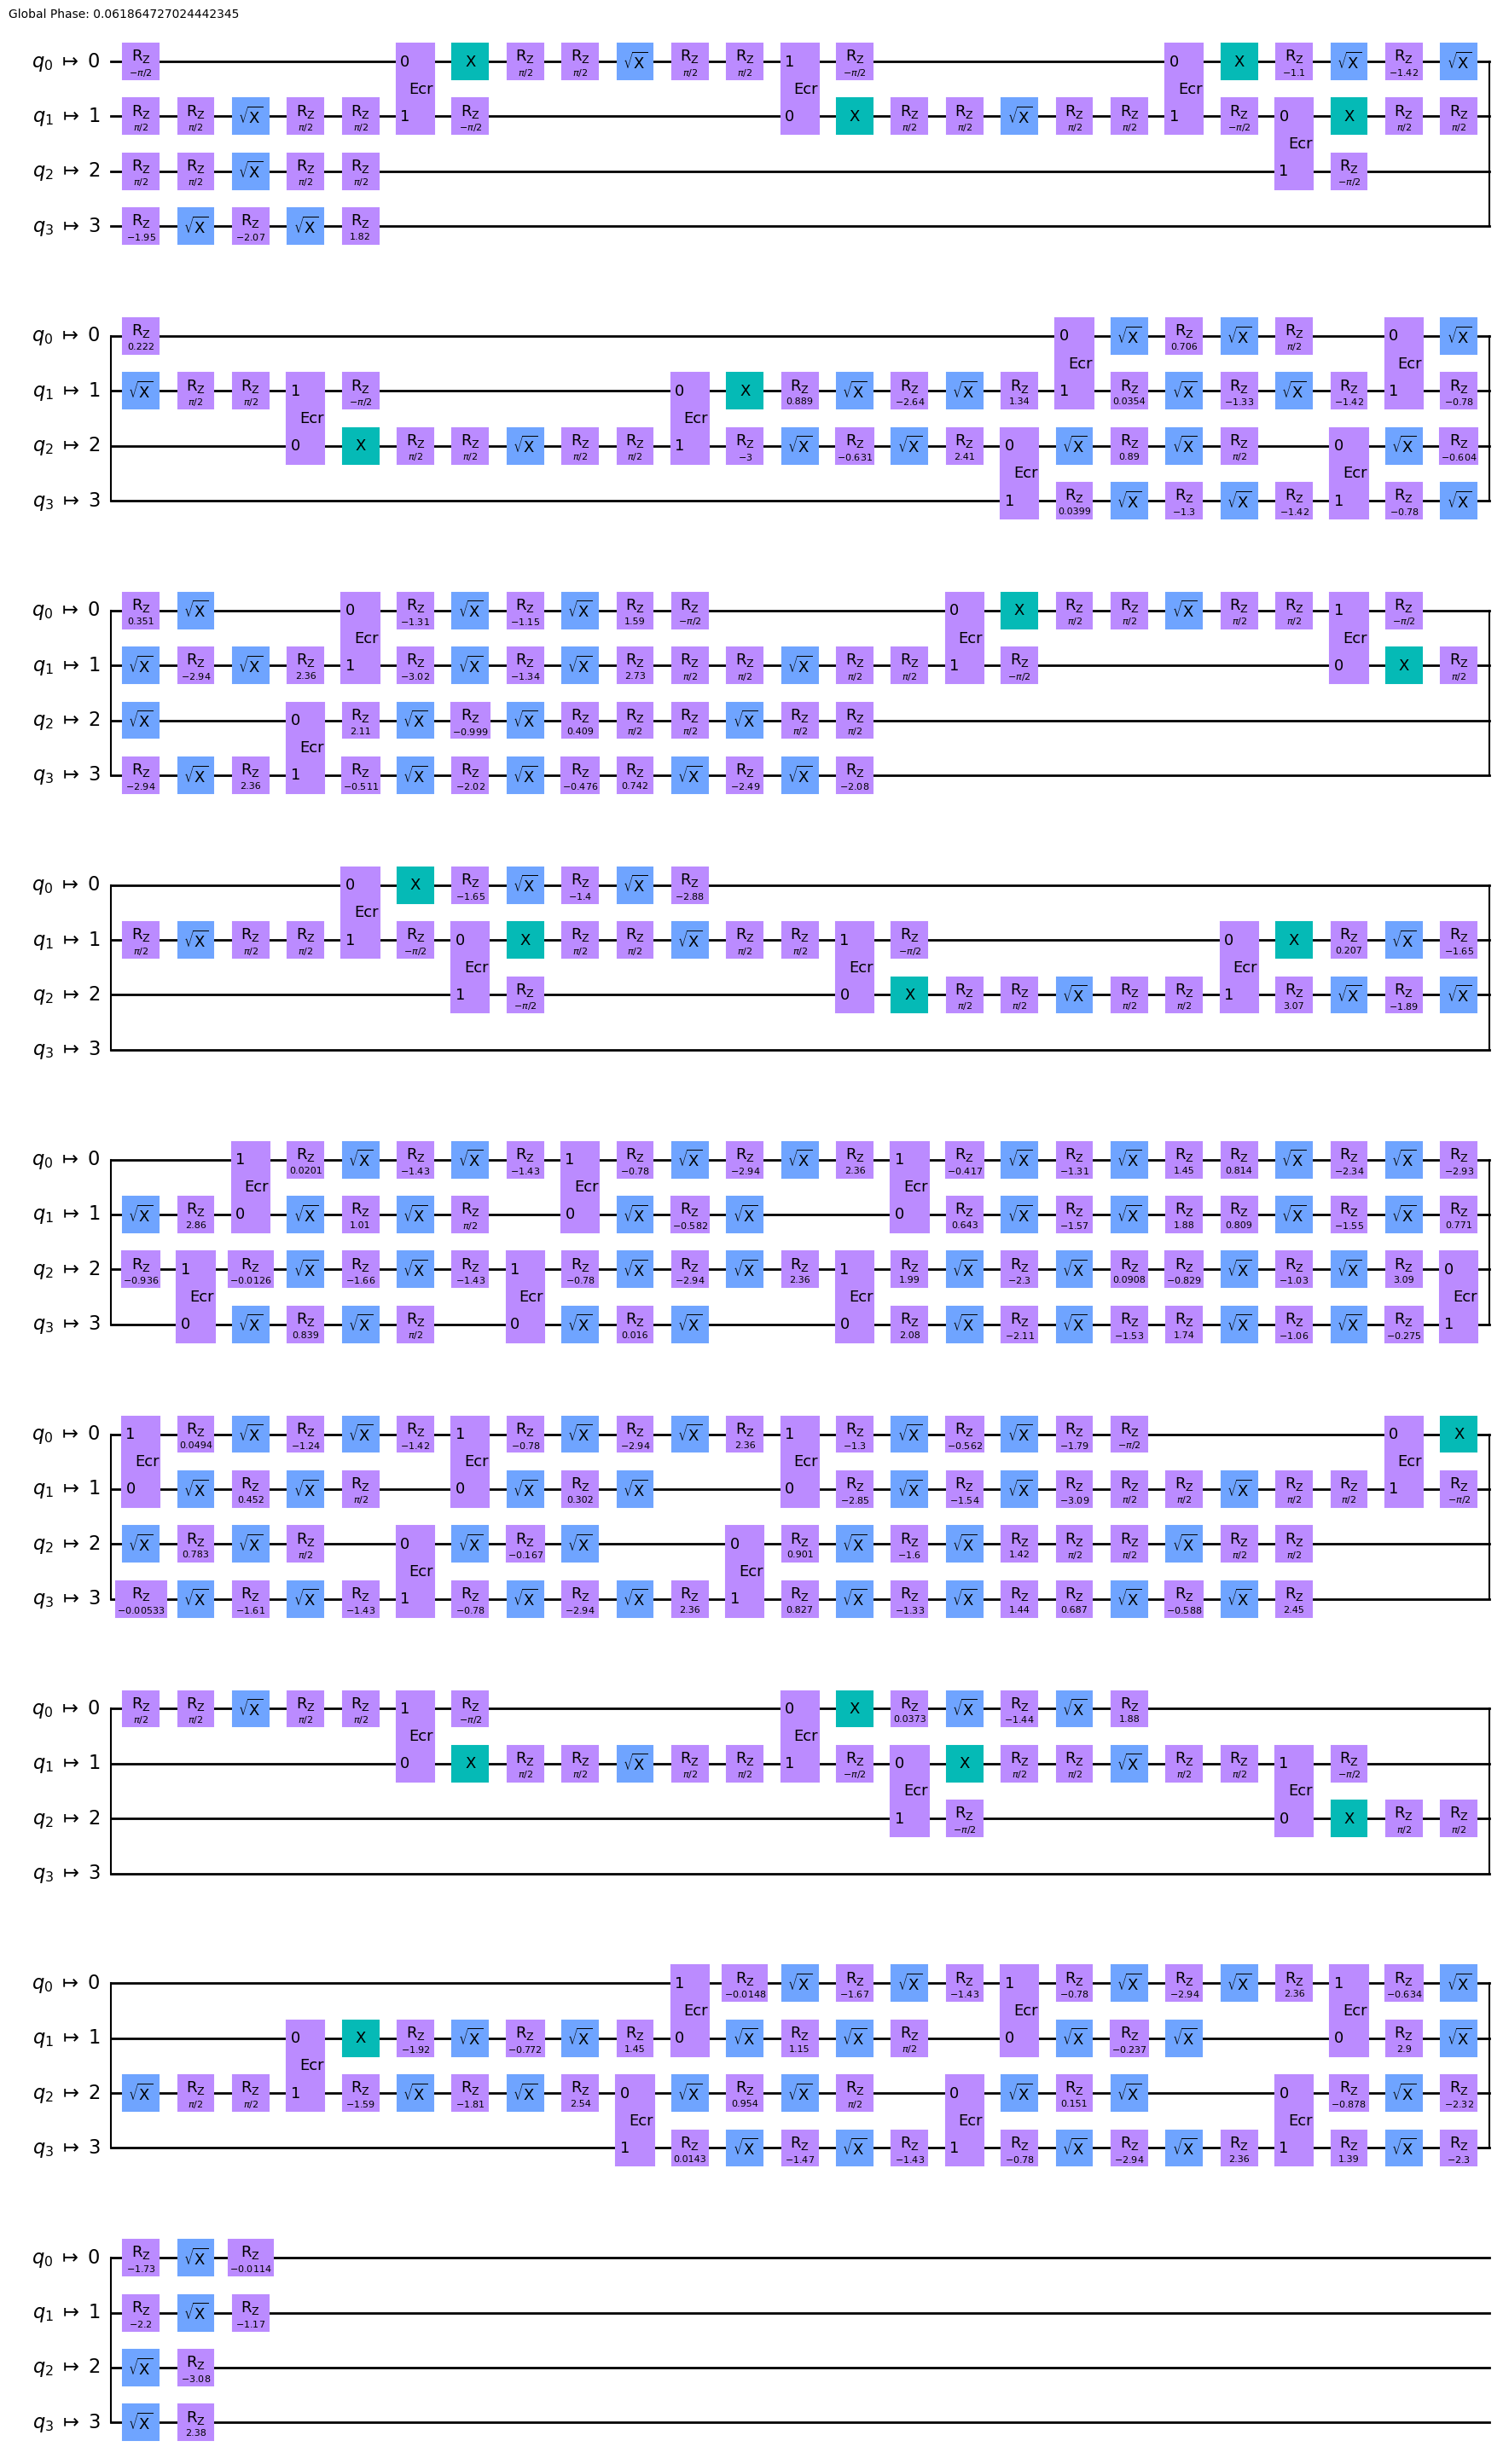

In [15]:
from qiskit import transpile
from qiskit.transpiler import CouplingMap
from qiskit.circuit.library import QuantumVolume

num_qubits = 4
basis_gates = ['ecr','sx','x','rz','id']
qv = QuantumVolume(num_qubits=num_qubits, depth=None, seed=0, classical_permutation=True) 

# This is the default QV
transpiled_qv = transpile(qv, basis_gates=basis_gates)

# ...But we want connectivity taken into account
edge_list = []
for i in range(num_qubits - 1):
    edge_list.append([i, i + 1])
    edge_list.append([i + 1, i])
coupling_map = CouplingMap(edge_list)

optimization_level = 0
transpiled_coupling_qv = transpile(
            qv,
            basis_gates=basis_gates,
            coupling_map=coupling_map,
            seed_transpiler=12345,
            optimization_level=optimization_level,
        )

transpiled_coupling_qv.draw("mpl")#, fold=-1)

The `no_end_to_end` does not avoid cases where 0-0 are together.

We could fix this by swapping X gates for SX gates at those points.

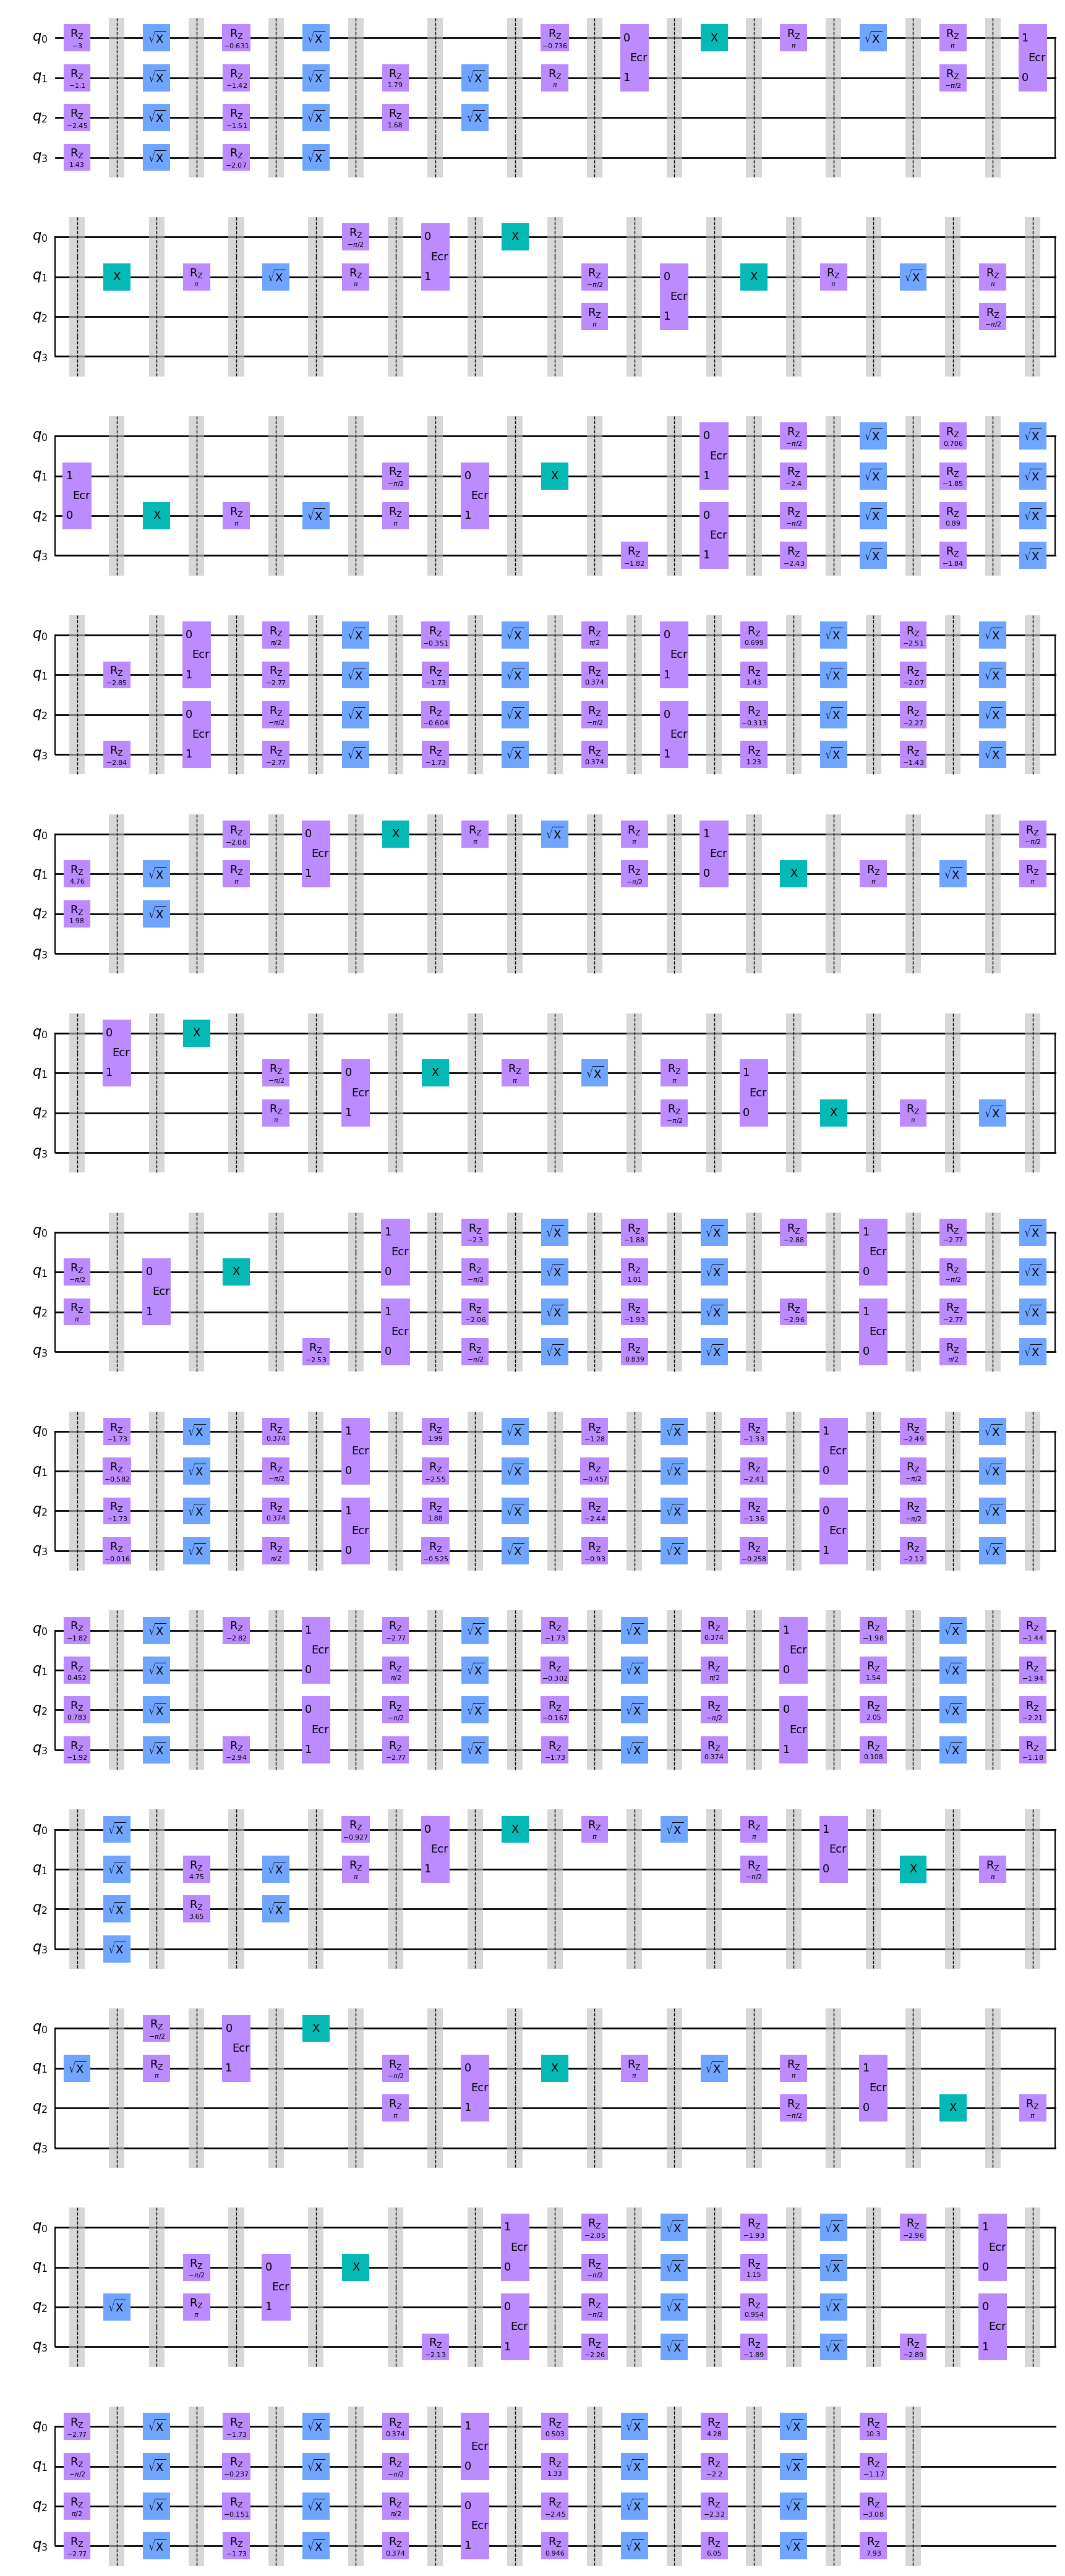

In [13]:
# ALI: Use different routing pass to get better density (less depth).
circ = ps.build_circuit(qv_moments, registers, insert_identities=False, barriers=True)
circ.draw('mpl')

# Schedules

In [ ]:
my_moments = qv_moments

In [ ]:
sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=cal_1qb_default,
    cr_gates=cal_2qb_default,
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt,
    insert_identities=True,
    verbose=True
)

robust_sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=cal_1qb_robust,
    cr_gates=cal_2qb_robust,
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt,
    insert_identities=True,
    verbose=False
)

mix_sched = ps.build_pulse_schedule(
    my_moments,
    qubit_gates=cal_1qb_default,
    cr_gates=cal_2qb_robust,
    registers=registers,
    backend=backend,
    name="hamiltonian-simulation",
    dt=dt,
    insert_identities=True,
    verbose=False
)

# Check durations
assert robust_sched.duration == sched.duration

# Would be nice to disable phase channels when plotting
# sched.draw()

# Solvers

In [ ]:
solver_r0 = ps.build_solver(
    registers,
    backend,
    include_crosstalk=False,
    include_dissipation=False
)

solver_rx0 = ps.build_solver(
    registers,
    backend,
    include_crosstalk=True,
    include_dissipation=False
)

solver_rx = ps.build_solver(
    registers,
    backend,
    include_crosstalk=True,
    include_dissipation=True
)

# Unitary simulations

In [ ]:
# measure after each non-phase moment
measure_times = dt * np.cumsum(
    ps.durations_of_moments(my_moments, duration_1qb, duration_2qb)
)[[ps.get_moment_case(m) != "phase" for m in my_moments]]
# and at the end time...
measure_times = np.append(measure_times, sched.duration * dt)


# targets at measure times
Uts = []
for i, m in enumerate(my_moments):
    if ps.get_moment_case(m) != "phase":
        Uts.append(ps.build_operator(my_moments[0:i+1], registers))
# and at the end time...
Uts.append(qk.quantum_info.Operator(ps.build_circuit(my_moments, registers)))

# Target
target = Uts[-1]

In [ ]:
# # measure after each 2qb moment
# measure_times = dt * np.cumsum(
#     ps.durations_of_moments(my_moments, duration_1qb, duration_2qb)
# )[[ps.get_moment_case(m) == "ecr" for m in my_moments]]


# # targets at measure times
# Uts = []
# for i, m in enumerate(my_moments):
#     if ps.get_moment_case(m) == "ecr":
#         Uts.append(ps.build_operator(my_moments[0:i+1], registers))

## No dissipation

This new result accumulates crosstalk due to the (0 <- 1) (2->3) ECR gates. See github issue.

In [ ]:
y0 = ps.qiskit_identity_operator(len(registers))

labels = ["default", "robust (rotary)", "default (rotary)"]
all_schedules = [sched, robust_sched, mix_sched]

# ==========

solver_rx0.model.evaluation_mode = "sparse"
res_x0 = solver_rx0.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=all_schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))

for i, ell in enumerate(labels):
    print(f"\tInfidelity of {ell}: ", 1 - qk.quantum_info.process_fidelity(res_x0[i].y[-1], target))

In [ ]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')


for iax in range(1):
    ax = axes[iax]

    for i, res in enumerate(res_x0):
        infids = [0]
        for r, t in zip(res.y, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r), qk.quantum_info.Operator(t)))
        ax.plot(np.hstack([0, *measure_times]), infids, label=labels[i], marker=".")

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        # ax.set_ylim([0, .001])
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

In [ ]:
stop_here

# OTHER PLOTS (IGNORE)

## No crosstalk

In [ ]:
print("Case 1: No crosstalk, no decay")

y0 = ps.qiskit_identity_operator(len(registers))

solver_r0.model.evaluation_mode = "sparse"
res_0 = solver_r0.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=[sched.duration * dt],
    y0=y0,
    signals=[sched, robust_sched, mix_sched],
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = ps.build_operator(my_moments, registers)

print(
    "\tInfidelity of default schedule: ",
    1 - qk.quantum_info.process_fidelity(res_0[0].y[-1], target),
)
print(
    "\tInfidelity of robust schedule: ",
    1 - qk.quantum_info.process_fidelity(res_0[1].y[-1], target),
)
print(
    "\tInfidelity of mixed schedule: ",
    1 - qk.quantum_info.process_fidelity(res_0[2].y[-1], target),
)


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=[10, 4])
fig.suptitle("Hamiltonian Simulation: No crosstalk, No Decoherence")

n = 10
layers = np.arange(1, n + 1)
Uts = list(itertools.accumulate(np.repeat([target], n, axis=0), np.matmul))

for iax in range(2):
    ax = axes[iax]

    for i, r in enumerate(res_0):
        Ufs = itertools.accumulate(np.repeat([r.y[-1]], n, axis=0), np.matmul)
        infids = []
        for r, t in zip(Ufs, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r), qk.quantum_info.Operator(t)))
        ax.plot(layers, infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Layers")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

## With decoherence

In [ ]:
# y0 = ps.qiskit_identity_operator(len(registers), open=True)
y0 = ps.qiskit_ground_state(len(registers), open=True)

labels = ["default", "robust (rotary)", "default (rotary)"]
schedules = [sched, robust_sched, mix_sched]

solver_rx.model.evaluation_mode = "sparse_vectorized"
res_x = solver_rx.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))
y_target = y0.evolve(target)

# for i in range(len(res_x)):
#     print(
#         f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.process_fidelity(res_x[0].y[-1], target)}"
#     )

for i in range(len(res_x)):
    print(
        f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.state_fidelity(res_x[i].y[-1], y_target)}"
    )

In [ ]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')


for iax in range(1):
    ax = axes[iax]

    for i, res in enumerate(res_x):
        infids = [0]
        # if labels[i] == "default":
        #     continue
        for r, t in zip(res.y, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r), qk.quantum_info.Operator(t)))
        ax.plot(np.hstack([0, *measure_times]), infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.0001, color="black", linestyle="-", lw=0.5)
    # ax.axhline(1e-10, color="black", linestyle="-", lw=0.5)


    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        # ax.set_ylim([0, .001])
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

In [ ]:
print("Case 3.5: Decoherence")

# y0 = ps.qiskit_identity_operator(len(registers), open=True)
y0 = ps.qiskit_ground_state(len(registers), open=True)

labels = ["decoherence limit, default", "decoherence limit, robust (rotary)", "decoherence limit, default (rotary)"]
schedules = [sched, robust_sched, mix_sched]

solver_r.model.evaluation_mode = "sparse_vectorized"
res_r = solver_r.solve(
    t_span=[0.0, sched.duration * dt],
    t_eval=measure_times,
    y0=y0,
    signals=schedules,
    atol=1e-9,
    rtol=1e-9,
    method="jax_odeint",
)

# Compute fidelity (we can use our circuit to compute the target)
target = qk.quantum_info.Operator(ps.build_circuit(my_moments, registers))
y_target = y0.evolve(target)

for i in range(len(res_r)):
    print(
        f"\tInfidelity of {labels[i]} schedule: {1 - qk.quantum_info.state_fidelity(res_r[i].y[-1], y_target)}"
    )

In [ ]:
# Save the results
# format datetime for a file name
now = datetime.now()
dt_string = now.strftime("%Y-%m-%d-%H-%M-%S")
pkl.dump(
    {
        "res_x0": res_x0,
        "res_x": res_x,
        "res_r": res_r,
        "measure_times": measure_times,
        "Uts": Uts,
    },
    open(f"{dt_string}-scale-{scale}-crosstalk-decoherence.pkl", "wb"),
)

In [ ]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
axes[0].set_title("Hamiltonian simulation: Crosstalk and decoherence", loc='left')

yts = [y0.evolve(Ut) for Ut in Uts]
labels = ["default", "robust (rotary)", "default (rotary)"]
# labels = ["decoherence limit, default", "decoherence limit, robust (rotary)", "decoherence limit, default (rotary)"]

for iax in range(len(axes)):
    ax = axes[iax]
    tab10 = plt.get_cmap("tab10")
    for i, (rx, rr) in enumerate(zip(res_x, res_r)):
        infids = [0]
        infids_decoh = [0]
        for j, t in enumerate(yts):
            infids.append(1 - qk.quantum_info.state_fidelity(rx.y[j], t))
            infids_decoh.append(1 - qk.quantum_info.state_fidelity(rr.y[j], t))
        if i == 0:
            ax.plot(np.hstack([0, *measure_times]), infids_decoh, c='k', ls='--',lw=1, zorder=10, label="decoherence limit")
        ax.plot(np.hstack([0, *measure_times]), infids, c=tab10(i), label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

In [ ]:
n = 50

fig, axes = plt.subplots(1, 2, figsize=[7, 4])#, dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# fig.suptitle("Hamiltonian simulation: Crosstalk and decoherence")
axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')

layers = np.arange(1, n + 1)
Uts = list(itertools.accumulate(np.repeat([target], n, axis=0), np.matmul))

for iax in range(len(axes)):
    ax = axes[iax]

    for i, r in enumerate(res_x):
        Ufs = itertools.accumulate(np.repeat([r.y[-1]], n, axis=0), np.matmul)
        infids = []
        for r, t in zip(Ufs, Uts):
            infids.append(1 - qk.quantum_info.process_fidelity(r, qk.quantum_info.Operator(t)))
        ax.plot(layers, infids, label=labels[i], marker=".")

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Layers")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

## Combo plot

In [ ]:
# Load from file
two_res_x0 = []
two_res_x = []
two_res_r = []
with open("../playground/2024-03-01-15-06-33-scale-10-crosstalk-decoherence.pkl", "rb") as f:
    data = pkl.load(f)
    two_res_x0.append(data['res_x0'])
    two_res_x.append(data['res_x'])
    two_res_r.append(data['res_r'])

with open("../playground/2024-03-01-15-36-13-scale-1.0-crosstalk-decoherence.pkl", "rb") as f:
    data = pkl.load(f)
    two_res_x0.append(data['res_x0'])
    two_res_x.append(data['res_x'])
    two_res_r.append(data['res_r'])

In [ ]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
# axes[0].set_title("Hamiltonian simulation: Crosstalk, No decoherence", loc='left')


for iax in range(1):
    ax = axes[iax]
    for i in range(len(labels)):
        res1 = two_res_x0[0][i]
        res2 = two_res_x0[1][i]
        infids1 = [0]
        infids2 = [0]
        for r1, r2, t in zip(res1.y, res2.y, Uts):
            infids1.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r1), qk.quantum_info.Operator(t)))
            infids2.append(1 - qk.quantum_info.process_fidelity(qk.quantum_info.Operator(r2), qk.quantum_info.Operator(t)))
    
        x = np.hstack([0, *measure_times])
        ax.fill_between(x, y1=infids1, y2=infids2, color=tab10(i), alpha=0.33)
        ax.plot(x, infids1, label=labels[i], marker=".", color=tab10(i))
        ax.plot(x, infids2, marker=".", color=tab10(i))

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.0001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")

In [ ]:
fig, axes = plt.subplots(1, figsize=[7, 4], dpi=300)
axes = axes if isinstance(axes, np.ndarray) else [axes]
axes[0].set_title("Hamiltonian simulation: Crosstalk and decoherence", loc='left')

yts = [y0.evolve(Ut) for Ut in Uts]
labels = ["default", "robust (rotary)", "default (rotary)"]
# labels = ["decoherence limit, default", "decoherence limit, robust (rotary)", "decoherence limit, default (rotary)"]

for iax in range(len(axes)):
    ax = axes[iax]
    tab10 = plt.get_cmap("tab10")
    for i in range(len(labels)):

        infids1 = [0]
        infids2 = [0]
        infids_decoh = [0]
        for j, t in enumerate(yts):
            infids1.append(1 - qk.quantum_info.state_fidelity(two_res_x[0][i].y[j], t))
            infids2.append(1 - qk.quantum_info.state_fidelity(two_res_x[1][i].y[j], t))
            infids_decoh.append(1 - qk.quantum_info.state_fidelity(rr.y[j], t))
        if i == 0:
            ax.plot(np.hstack([0, *measure_times]), infids_decoh, c='k', ls='--',lw=1, zorder=10, label="decoherence limit")
        x = np.hstack([0, *measure_times])
        ax.fill_between(x, y1=infids1, y2=infids2, color=tab10(i), alpha=0.33)
        ax.plot(x, infids1, label=labels[i], marker=".", color=tab10(i))
        ax.plot(x, infids2, marker=".", color=tab10(i))

    ax.axhline(0.1, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.01, color="black", linestyle="-", lw=0.5)
    ax.axhline(0.001, color="black", linestyle="-", lw=0.5)

    ax.set_xlabel("Time")
    if iax == 0:
        ax.legend(loc="lower right")
        ax.set_yscale("log")
        ax.set_ylabel("Infidelity")
    else:
        ax.set_ylabel("Infidelity")
        ax.legend(loc="upper left")
        ax.set_yscale("linear")